# Practice 11 — Object Detection and Segmentation

**Goal:** run a pretrained detector and a segmentation model, read what they return — *where*, not only *what* — and score the detector with mAP.

| Task | Output per object | Numbers per object |
|:---|:---|:---|
| Classification | one label for the whole image | 1 class index |
| Object detection | one axis-aligned box | 4 coordinates + class + confidence |
| Instance segmentation | one per-pixel mask | a 0/1 grid + class + confidence |

- Nothing is trained here → the weights arrive pretrained on the 80 COCO classes

---
## Step 0. Setup

- `ultralytics` → the YOLO models with their `predict` and `val` methods
- A path given to `YOLO(...)` → the weights are downloaded there, not into the working directory

In [1]:
import subprocess
import sys

try:
    import ultralytics
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'], check=True)
    import ultralytics

print(f'ultralytics {ultralytics.__version__}')

ultralytics 8.4.194


In [2]:
import urllib.request
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO

np.random.seed(42)
torch.manual_seed(42)

# the weights and the images are saved under these two folders; val() writes its runs to runs/
BUILD = Path('build')
DATA = Path('data')
BUILD.mkdir(exist_ok=True)
DATA.mkdir(exist_ok=True)

print(f'GPU available : {torch.cuda.is_available()}')

GPU available : True


image shape : (1380, 2070, 3)   height, width, channels


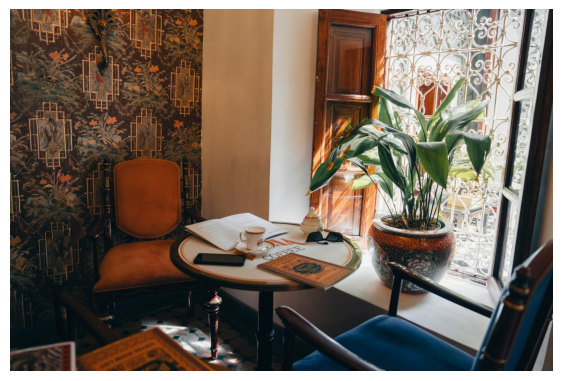

In [3]:
url_room = 'https://images.unsplash.com/photo-1760681557777-bfac1f18cf90?ixlib=rb-4.1.0&auto=format&fit=crop&q=80&w=2070'
image_path_room = DATA / 'room.jpg'
if not image_path_room.exists():
    urllib.request.urlretrieve(url_room, image_path_room)

url_bus = 'https://ultralytics.com/images/bus.jpg'
image_path_bus = DATA / 'bus.jpg'
if not image_path_bus.exists():
    urllib.request.urlretrieve(url_bus, image_path_bus)

image_room = np.array(Image.open(image_path_room).convert('RGB'))
print(f'image shape : {image_room.shape}   height, width, channels')

plt.figure(figsize=(7, 5))
plt.imshow(image_room)
plt.axis('off')
plt.show()

---
## Step 1. Running the Detector

- `yolo11n` → the smallest YOLO11, already knows the 80 COCO classes
- `conf=0.25` → drops detections below 25% confidence
- `predict` returns a list, one `Results` per input image; `result.plot()` draws its boxes (BGR → channels reversed for matplotlib)

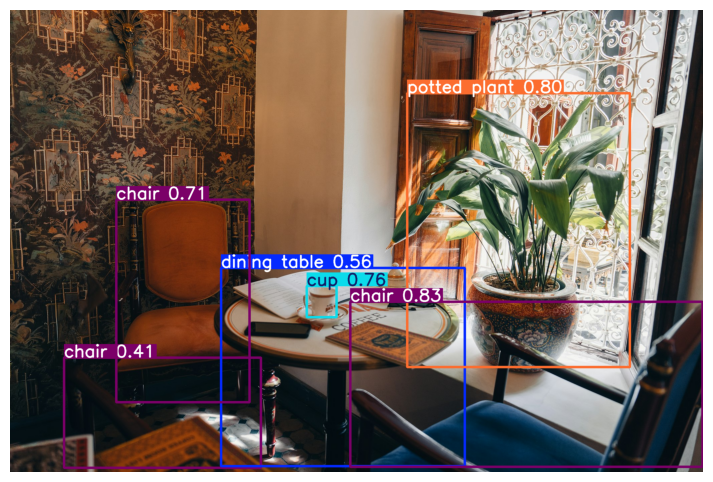

In [4]:
detection_model = YOLO(str(BUILD / 'yolo11n.pt'))
detection_results = detection_model.predict(source=str(image_path_room), conf=0.25, verbose=False)
detection_result = detection_results[0]  # we have only one result from one image

plt.figure(figsize=(9, 6))
plt.imshow(detection_result.plot()[:, :, ::-1])  # ::-1 reverses the channels, BGR -> RGB
plt.axis('off')
plt.show()

---
## Step 2. What Is Inside `result.boxes`

- `boxes[0]` prints every attribute of the first object

| Attribute | Shape | Meaning |
|:---|:---|:---|
| `xyxy` | (N, 4) | corners in pixels, `(x1, y1, x2, y2)` |
| `xywh` · `xyxyn` · `xywhn` | (N, 4) | centre–size form; `n` = divided by the image size |
| `conf` | (N,) | confidence |
| `cls` | (N,) | class index, a float → `int()` for `names` |
| `data` | (N, 6) | all of the above in one tensor |

In [5]:
print(detection_result.boxes[0])

ultralytics.engine.results.Boxes object with attributes:

cls: tensor([56.], device='cuda:0')
conf: tensor([0.8330], device='cuda:0')
data: tensor([[1.0166e+03, 8.7137e+02, 2.0690e+03, 1.3650e+03, 8.3303e-01, 5.6000e+01]], device='cuda:0')
id: None
is_track: False
orig_shape: (1380, 2070)
shape: torch.Size([1, 6])
xywh: tensor([[1542.7952, 1118.1709, 1052.3307,  493.6074]], device='cuda:0')
xywhn: tensor([[0.7453, 0.8103, 0.5084, 0.3577]], device='cuda:0')
xyxy: tensor([[1016.6298,  871.3672, 2068.9604, 1364.9746]], device='cuda:0')
xyxyn: tensor([[0.4911, 0.6314, 0.9995, 0.9891]], device='cuda:0')


- `result.names` → the 80 class names by index; one line per object with its confidence

In [6]:
for index in range(len(detection_result.boxes)):
    class_name = detection_result.names[int(detection_result.boxes.cls[index])]
    confidence = float(detection_result.boxes.conf[index])
    print(f'{class_name:<14s} {confidence:.3f}')

chair          0.833
potted plant   0.801
cup            0.760
chair          0.710
dining table   0.564
chair          0.412


---
## What `source` Accepts

| `source` | Form |
|:---|:---|
| path | `str`: an image file, a folder or a video |
| URL | `str` ending in an image extension (`.jpg`, …) → downloaded next to the notebook |
| `PIL.Image` | as loaded |
| `numpy` array | `(H, W, 3)` `uint8` in **BGR** order (OpenCV convention) |
| `torch` tensor | `(B, 3, H, W)` float in [0, 1], RGB |

- A link without an extension (the Unsplash one) works only in recent library versions; older ones take it for a video stream and hang → download it yourself, as Step 0 did

In [7]:
print(np.shape(image_room))

(1380, 2070, 3)


In [8]:
# Method 1: path
# source = str(image_path_room)

# Method 2: URL, ends in .jpg (url_room has no extension and hangs in older library versions)
# source = url_room

# Method 3: PIL image
# source = Image.fromarray(image_room)

# Method 4: numpy array, BGR copy of the RGB array
source = image_room[:, :, ::-1].copy() # ::-1 read RGB as BGR

print(np.shape(source))
result_from_source = detection_model.predict(source=source, conf=0.25, verbose=False)[0]
print(result_from_source.boxes[0])

(1380, 2070, 3)
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([56.], device='cuda:0')
conf: tensor([0.8330], device='cuda:0')
data: tensor([[1.0166e+03, 8.7137e+02, 2.0690e+03, 1.3650e+03, 8.3303e-01, 5.6000e+01]], device='cuda:0')
id: None
is_track: False
orig_shape: (1380, 2070)
shape: torch.Size([1, 6])
xywh: tensor([[1542.7952, 1118.1709, 1052.3307,  493.6074]], device='cuda:0')
xywhn: tensor([[0.7453, 0.8103, 0.5084, 0.3577]], device='cuda:0')
xyxy: tensor([[1016.6298,  871.3672, 2068.9604, 1364.9746]], device='cuda:0')
xyxyn: tensor([[0.4911, 0.6314, 0.9995, 0.9891]], device='cuda:0')


---
## Step 3. Drawing from the Coordinates

- The first row of `boxes.xyxy` → one matplotlib rectangle; `plot()` does this for every row

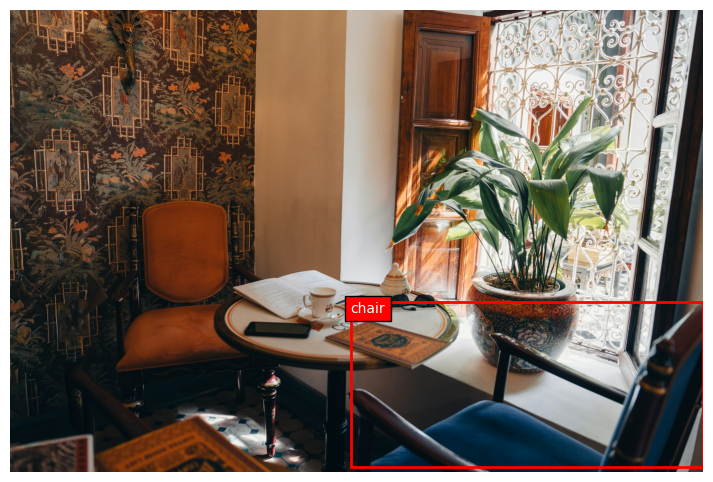

In [9]:
x1, y1, x2, y2 = detection_result.boxes.xyxy[0].cpu().numpy()
class_name = detection_result.names[int(detection_result.boxes.cls[0])]

plt.figure(figsize=(9, 6))
plt.imshow(image_room)
plt.gca().add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='red', linewidth=2))
plt.text(x1, y1, class_name, color='white', va='top', bbox=dict(facecolor='red'))
plt.axis('off')
plt.show()

- `(x1, y1)` is the top-left corner and `(x2, y2)` the bottom-right → width `x2 - x1`, height `y2 - y1`

---
## Step 4. The Confidence Threshold

- Only `conf` changes between the two calls → the boxes that survive, their confidences in the labels

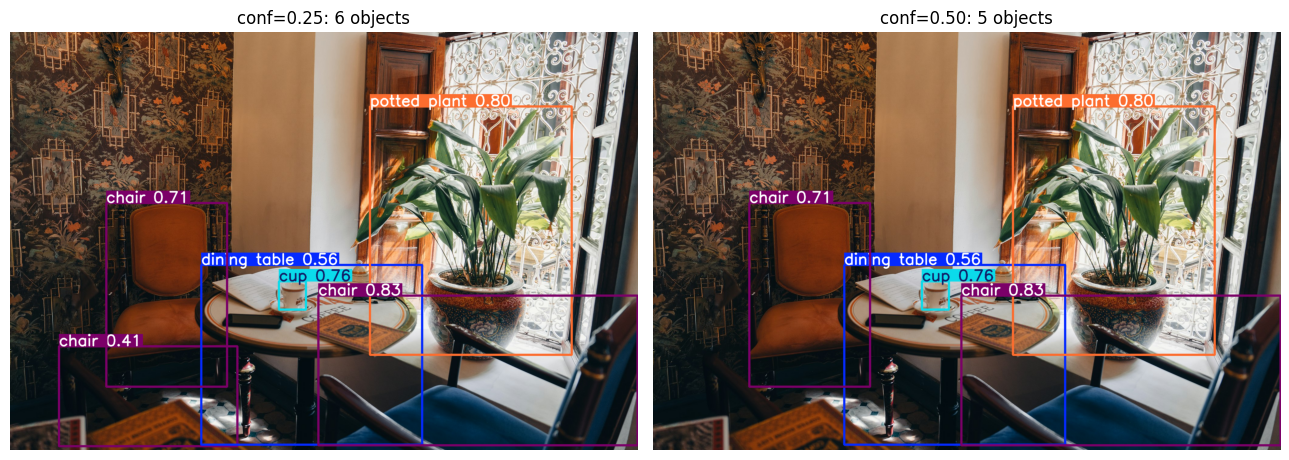

In [10]:
result_25 = detection_model.predict(source=str(image_path_room), conf=0.25, verbose=False)[0]
result_50 = detection_model.predict(source=str(image_path_room), conf=0.50, verbose=False)[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(result_25.plot()[:, :, ::-1])
axes[0].set_title(f'conf=0.25: {len(result_25.boxes)} objects')

axes[1].imshow(result_50.plot()[:, :, ::-1])
axes[1].set_title(f'conf=0.50: {len(result_50.boxes)} objects')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- `chair` 0.41 is the only detection below 0.50 → it is gone on the right, the other five stay

---
## Step 5. NMS

- The detector proposes many boxes → several pass `conf` on the same object
- NMS (non-maximum suppression) keeps the most confident box of a class and removes the others overlapping it by IoU above `iou`, a `predict` argument with default 0.7
- `iou=1.0` → nothing is removed: the raw list behind Step 1

iou=1.0 (NMS off) : 52 boxes
iou=0.7 (default) :  6 boxes


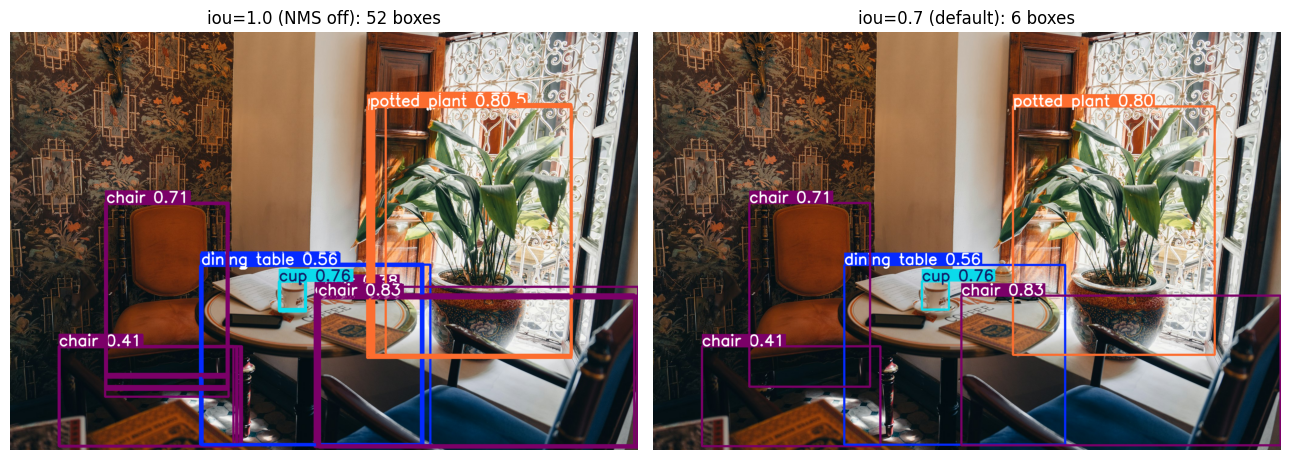

In [11]:
raw_result = detection_model.predict(source=str(image_path_room), conf=0.25, iou=1.0, verbose=False)[0]

print(f'iou=1.0 (NMS off) : {len(raw_result.boxes):2d} boxes')
print(f'iou=0.7 (default) : {len(detection_result.boxes):2d} boxes')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(raw_result.plot()[:, :, ::-1])
axes[0].set_title(f'iou=1.0 (NMS off): {len(raw_result.boxes)} boxes')

axes[1].imshow(detection_result.plot()[:, :, ::-1])
axes[1].set_title(f'iou=0.7 (default): {len(detection_result.boxes)} boxes')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- Left: 52 boxes pass `conf=0.25`, many of them on the same chair, cup, plant or table
- Right: NMS keeps one box per object → the 6 of Step 1

---
## Step 6. Scoring the Detector: mAP

- Scoring needs labelled boxes → `coco8`, 8 COCO images with labels, 4 for validation
- A YOLO dataset = `images/` and `labels/` with matching file names; one `.txt` per image, one line per object: `class cx cy w h`, centre and size over the image size
- The same three cells score any dataset in this layout, yours included

coco8/images/train  4 files
coco8/images/val    4 files
coco8/labels/train  4 files
coco8/labels/val    4 files

000000000036.txt
25 0.475759 0.414523 0.951518 0.672422
0 0.671279 0.617945 0.645759 0.726859


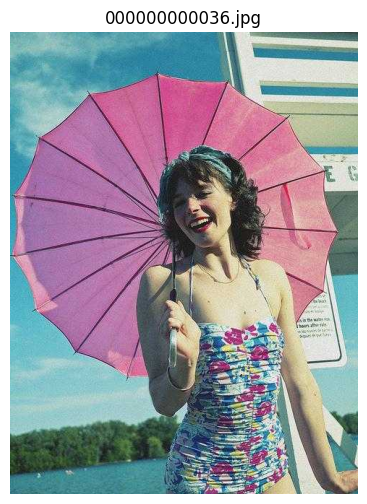

In [12]:
import zipfile

coco8_dir = DATA / 'coco8'
if not coco8_dir.exists():
    urllib.request.urlretrieve(
        'https://github.com/ultralytics/assets/releases/download/v0.0.0/coco8.zip', BUILD / 'coco8.zip')
    with zipfile.ZipFile(BUILD / 'coco8.zip') as archive:
        archive.extractall(DATA)

for folder in ['images/train', 'images/val', 'labels/train', 'labels/val']:
    n_files = len(list((coco8_dir / folder).glob('*')))
    print(f'coco8/{folder:<13s} {n_files} files')

label_path = coco8_dir / 'labels' / 'val' / '000000000036.txt'
print()
print(label_path.name)
print(label_path.read_text().strip())

plt.figure(figsize=(6, 6))
plt.imshow(Image.open(coco8_dir / 'images' / 'val' / '000000000036.jpg'))
plt.title('000000000036.jpg')
plt.axis('off')
plt.show()

- Two lines → two objects: class 25 = `umbrella`, class 0 = `person` in COCO's numbering; the boxes are drawn after scoring

- The library reads a dataset through a yaml file → where the `train` and `val` images are (labels are found by swapping `images` for `labels`) and what each class index means
- `names` → the 80 COCO classes in the model's order here; your own dataset lists its own

In [13]:
coco8_yaml_path = (DATA / 'coco8.yaml').resolve()

# the two folders are written relative to the folder this file sits in
with open(coco8_yaml_path, 'w', encoding='utf-8') as yaml_file:
    yaml_file.write('train: coco8/images/train\n')
    yaml_file.write('val: coco8/images/val\n')
    yaml_file.write('names:\n')
    for class_index, class_name in detection_model.names.items():
        yaml_file.write(f'  {class_index}: {class_name}\n')

# 83 lines: two folders, names:, then the 80 names
yaml_lines = coco8_yaml_path.read_text().splitlines()
for line in yaml_lines[:5]:
    print(line)
print('  ...')
print(yaml_lines[-1])

train: coco8/images/train
val: coco8/images/val
names:
  0: person
  1: bicycle
  ...
  79: toothbrush


- `val()` scores the detector on the `val` images → precision, recall and mAP per class
- mAP@50 → a match needs IoU ≥ 0.5; mAP@50-95 → averaged over IoU 0.5 to 0.95, rewarding tight boxes
- `name` → the run folder `runs/detect/coco8`, where `val()` saves its pictures

In [14]:
coco_metrics = detection_model.val(data=str(coco8_yaml_path), name='coco8')

print()
print(f'mAP@50    : {coco_metrics.box.map50:.3f}')
print(f'mAP@50-95 : {coco_metrics.box.map:.3f}')

Ultralytics 8.4.194  Python-3.11.13 torch-2.11.0+cu128 CUDA:0 (NVIDIA TITAN RTX, 24576MiB)


YOLO11n summary (fused): 100 layers, 2,616,248 parameters, 0 gradients, 6.5 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 439.5±251.4 MB/s, size: 54.0 KB)


val: Scanning D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\data\coco8\labels\val.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 15.7it/s 0.1s

...

              umbrella          1          1      0.569          1      0.995      0.995


          potted plant          1          1      0.847          1      0.995      0.895


Speed: 0.6ms preprocess, 7.8ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to D:\Main\00_Research\00_Python\00_Lecture\03_Advanced_AI-ME_Graduate\runs\detect\coco8-2



mAP@50    : 0.854
mAP@50-95 : 0.631


- One row per class that has labels, plus `all`: 4 images, 17 labelled objects, mAP@50 0.854
- mAP@50-95 0.631 → the same predictions scored again at IoU 0.55, 0.60, …, 0.95 and averaged; stricter matching, lower score
- 4 images → a demonstration; the real COCO validation set has 5,000

- The run folder holds the labels `val()` read, its predictions, and the precision–recall curve whose area per class is the AP

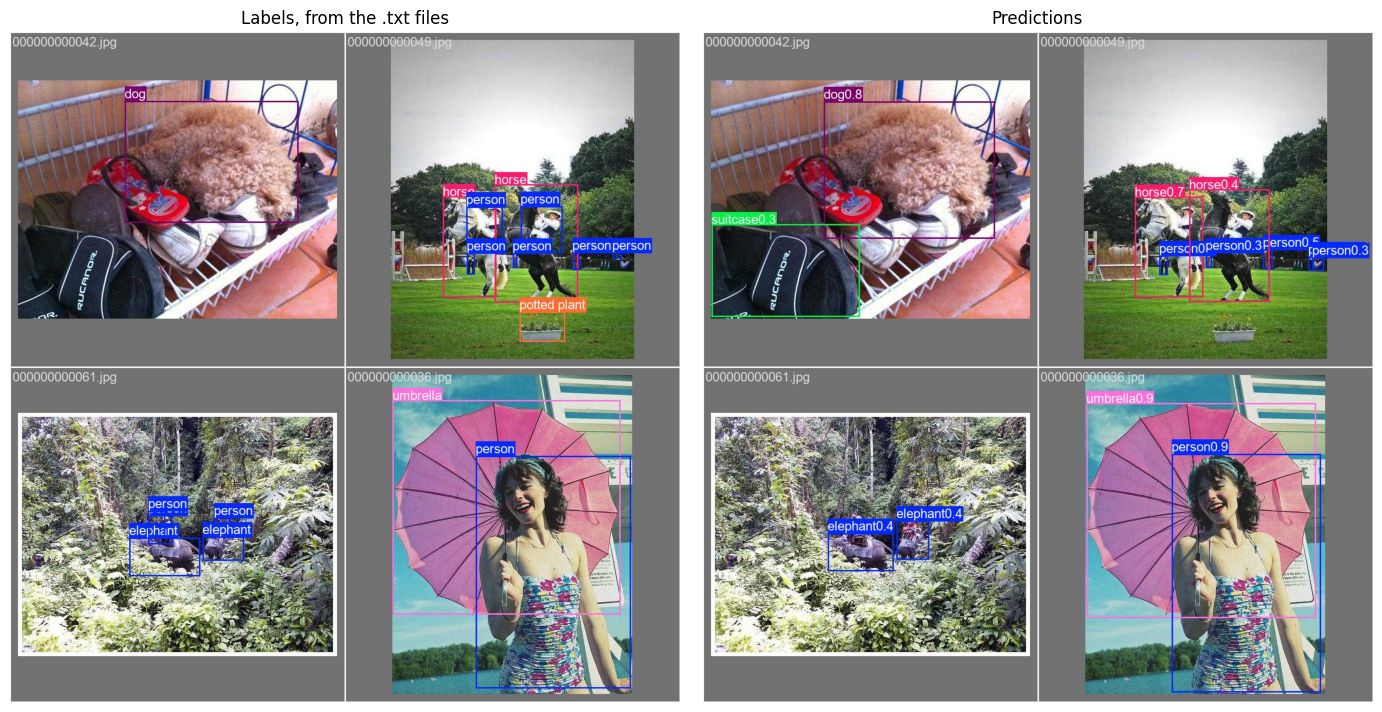

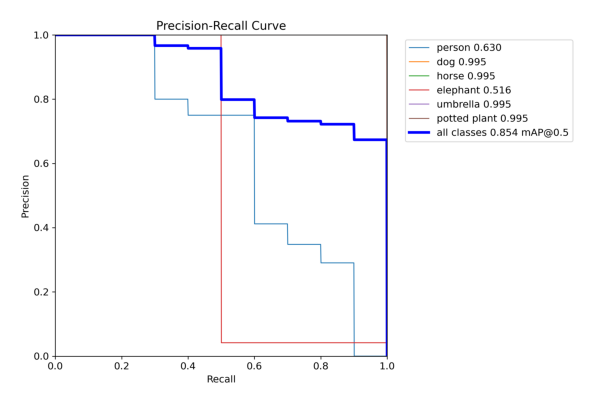

In [15]:
val_dir = Path(coco_metrics.save_dir)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(Image.open(val_dir / 'val_batch0_labels.jpg'))
axes[0].set_title('Labels, from the .txt files')

axes[1].imshow(Image.open(val_dir / 'val_batch0_pred.jpg'))
axes[1].set_title('Predictions')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.imshow(Image.open(val_dir / 'BoxPR_curve.png'))
plt.axis('off')
plt.show()

---
## Step 7. The Segmentation Model

- Everything the detector returns, plus one mask per object
- `retina_masks=True` → masks at the image size (the default is the smaller size the model ran at)

| Attribute | Shape | Meaning |
|:---|:---|:---|
| `boxes` | as in Step 2 | one box per object |
| `masks.data` | (N, H, W) | one 0/1 grid per object, 1 inside |

boxes      : (7, 6)
masks.data : (7, 1380, 2070)

chair          0.882
cup            0.846
potted plant   0.835
chair          0.728
remote         0.296
chair          0.278
dining table   0.266


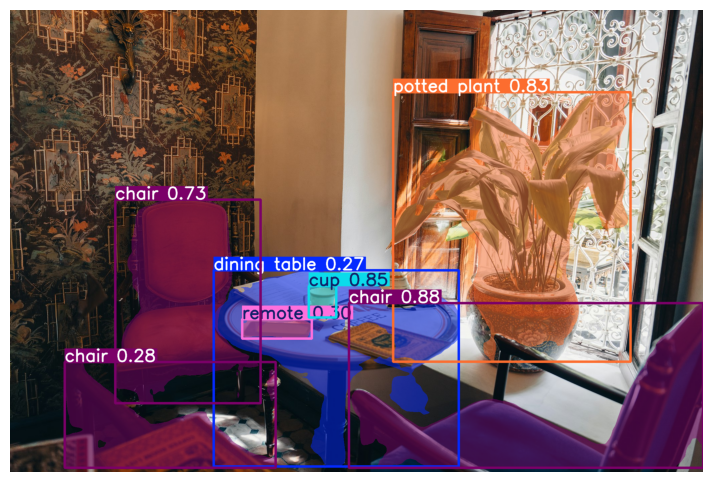

In [16]:
segmentation_model = YOLO(str(BUILD / 'yolo11n-seg.pt'))
segmentation_result = segmentation_model.predict(source=str(image_path_room), conf=0.25,
                                                 retina_masks=True, verbose=False)[0]

print(f'boxes      : {tuple(segmentation_result.boxes.shape)}')
print(f'masks.data : {tuple(segmentation_result.masks.data.shape)}')
print()
for index in range(len(segmentation_result.boxes)):
    class_name = segmentation_result.names[int(segmentation_result.boxes.cls[index])]
    confidence = float(segmentation_result.boxes.conf[index])
    print(f'{class_name:<14s} {confidence:.3f}')

plt.figure(figsize=(9, 6))
plt.imshow(segmentation_result.plot()[:, :, ::-1])
plt.axis('off')
plt.show()

- 7 objects, one more than the detector's 6 → another weights file, slightly different detections (`remote` 0.30)
- `plot()` colours by class → the chairs share one colour, yet `masks.data` holds a separate (1380, 2070) grid for each

- One mask per object, not per class → instance segmentation

| Task | One output covers |
|:---|:---|
| Semantic segmentation | every pixel of a class, as a single region |
| Instance segmentation | every pixel of one object, one mask per object |

---
## Step 8. One Mask

- `masks.data[2]` → the grid of one object, 1 inside and 0 outside, the size of the image

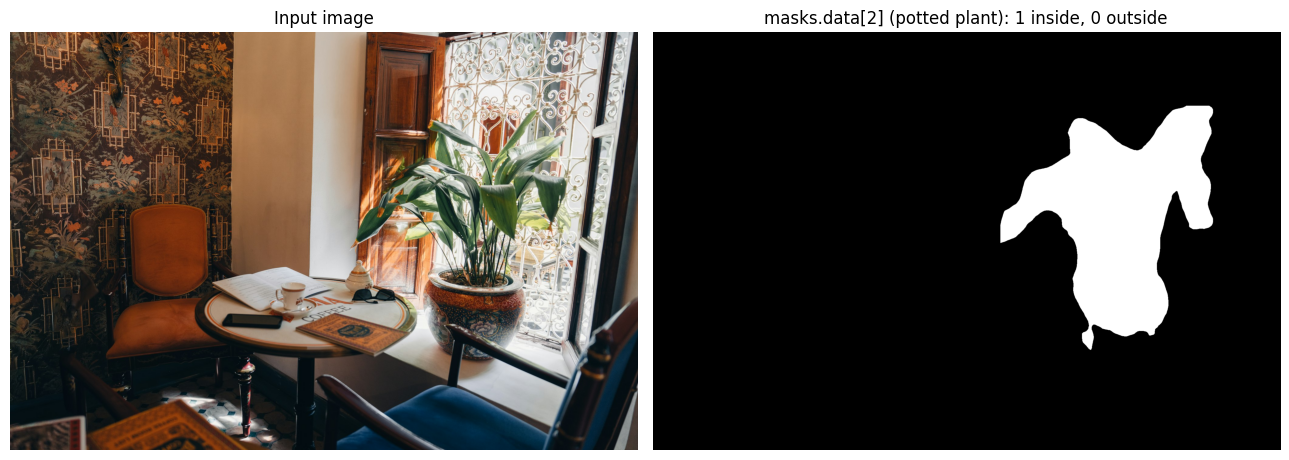

In [17]:
mask_index = 2
mask_class = segmentation_result.names[int(segmentation_result.boxes.cls[mask_index])]
one_mask = segmentation_result.masks.data[mask_index].cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(image_room)
axes[0].set_title('Input image')

axes[1].imshow(one_mask, cmap='gray')
axes[1].set_title(f'masks.data[{mask_index}] ({mask_class}): 1 inside, 0 outside')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- Box → where an object is; mask → which pixels are the object

---
## Step 9. What the Mask Buys You

- A mask gives the object's pixel count, a box only its extent
- Mask pixels / box pixels → how much of its box the object fills

In [18]:
print('object          mask pixels   box pixels   fill')
for index in range(len(segmentation_result.boxes)):
    class_index = int(segmentation_result.boxes.cls[index])
    x1, y1, x2, y2 = segmentation_result.boxes.xyxy[index].cpu().numpy()
    box_pixels = (x2 - x1) * (y2 - y1)
    mask_pixels = float(segmentation_result.masks.data[index].cpu().numpy().sum())
    fill = mask_pixels / box_pixels
    print(f'{segmentation_result.names[class_index]:<14s} {mask_pixels:11.0f} {box_pixels:12.0f}   {fill:.3f}')

object          mask pixels   box pixels   fill
chair               201373       520294   0.387
cup                   6389         7695   0.830
potted plant        279713       570222   0.491
chair               161082       264121   0.610
remote               10546        12171   0.866
chair               100735       199094   0.506
dining table        164716       428606   0.384


- Compact objects fill their box (`cup` 0.83, `remote` 0.87); wide or hollow ones do not (chairs, plant, table 0.38–0.61)
- Low fill → the box is mostly background

---
## Step 10. The Same Two Calls on Another Image

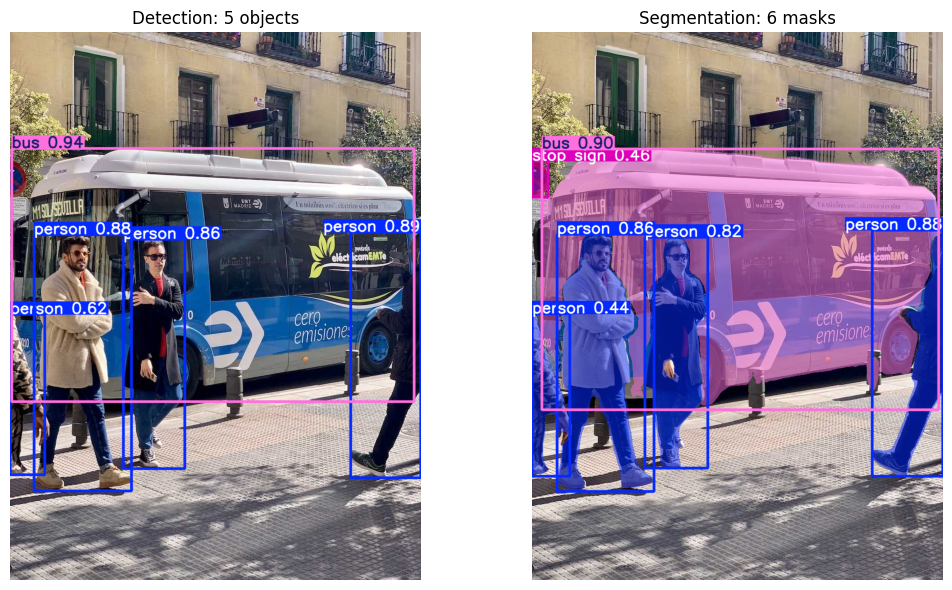

In [19]:
detection_bus = detection_model.predict(source=str(image_path_bus), conf=0.25, verbose=False)[0]
segmentation_bus = segmentation_model.predict(source=str(image_path_bus), conf=0.25,
                                              retina_masks=True, verbose=False)[0]

fig, axes = plt.subplots(1, 2, figsize=(11, 6))

axes[0].imshow(detection_bus.plot()[:, :, ::-1])
axes[0].set_title(f'Detection: {len(detection_bus.boxes)} objects')

axes[1].imshow(segmentation_bus.plot()[:, :, ::-1])
axes[1].set_title(f'Segmentation: {len(segmentation_bus.boxes)} masks')

for panel_axis in axes:
    panel_axis.axis('off')

plt.tight_layout()
plt.show()

- 5 boxes, 6 masks → the extra mask is the round sign at the left edge, labelled `stop sign` at 0.46, the nearest COCO class

---
## Summary

| Result | Holds | Note |
|:---|:---|:---|
| Detection | `boxes`: `xyxy` · `conf` · `cls`, one row per object | `conf` drops weak detections, `plot()` draws them |
| NMS | `iou` threshold, default 0.7 | duplicates collapse to the most confident box |
| mAP | `val(data=yaml, name=...)` → `images/` + `labels/` | @50 loose match, @50-95 tight boxes too |
| Segmentation | the same, plus `masks.data` | `retina_masks=True` → grids at the image size |

- Mask pixels / box pixels → how much of the box the object fills

---
## Exercises

1. `conf=0.7`, rerun the detection listing — which objects disappear, and what were their confidences?
2. Rerun `val()` with `conf=0.5` — does mAP@50 rise or fall, and why?
3. Draw only the object with the largest mask area, using the mask pixel counts from Step 9.

In [20]:
# Write your code here